# Sound scattering layer detector: demo

Supporting material for Barstein, Rogge, Olaisen, Abdelgayed, Dunn, Stevenson-Jones, Davies, Grimsmo and
Ludvigsen, *A Remote Operations Center Framework for Heterogeneous Robotic Zooplankton Sampling: System
Design and Field Case Study*.

This notebook runs the per-ping scattering-layer detector described in the paper on four hours of AutoNaut
echosounder data. It shows what each setting does, and it ends with a panel where you can tune the
settings yourself. The detector itself is in `ssl_detector.py`.

In [1]:
%matplotlib inline
from functools import lru_cache

import ipywidgets as w
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import ssl_detector as ssl

d = ssl.load_data()
sv, depth, time = d["sv"], d["depth"], d["time"]
P = ssl.DEFAULTS          # the settings of the paper's case study
print(f"{sv.shape[0]} pings, {time[0]} to {time[-1]} UTC")
print(f"depth {depth[0]:.2f} to {depth[-1]:.2f} m in {depth[1] - depth[0]:.1f} m bins")

5200 pings, 2024-06-05T21:26:00.653 to 2024-06-06T01:45:57.656 UTC
depth 0.45 to 99.95 m in 0.1 m bins


## The data

- AutoNaut uncrewed surface vehicle (NTNU), Simrad EK80 WBT Mini with a 200 kHz split-beam transducer
  (ES200-7CDK), CW pulses of 1.024 ms, not calibrated.
- 5 June 2024 21:26 to 6 June 01:46 UTC, off Mausund/Frøan, Norway: 5200 pings, about 3 s apart.
- Volume backscattering strength Sv (dB re 1 m⁻¹), averaged into 0.1 m depth bins (mean of the linear
  values). Depth is the range from the transducer.

The echosounder was not calibrated, so the absolute Sv values, and with them the thresholds below, apply
to this instrument only.

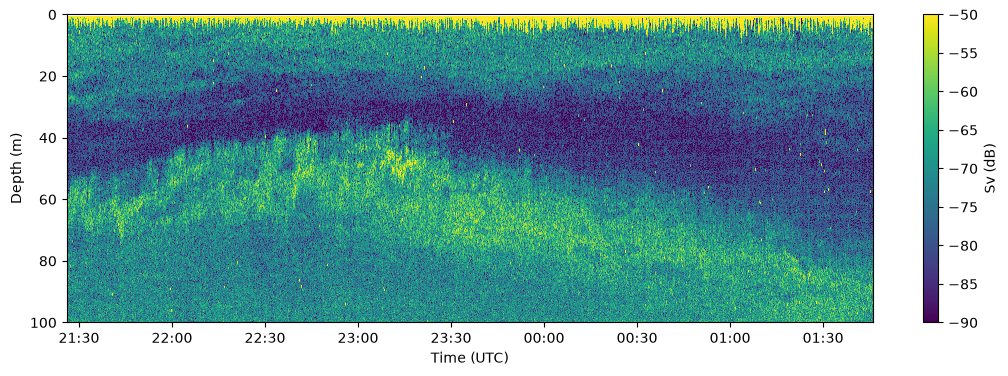

In [2]:
T = mdates.date2num(time)


def echogram(ax, r=None, median=1, top=100):
    """The echogram, with the detected bounds (white) and peak (red) of result r."""
    im = ax.imshow(sv.T, aspect="auto", cmap="viridis", vmin=-90, vmax=-50, interpolation="nearest",
                   extent=[T[0], T[-1], depth[-1], depth[0]])
    if r is not None:
        for k, c in (("z_u", "w"), ("z_l", "w"), ("z_peak", "r")):
            ax.plot(T, ssl.running_median(r[k], median), ".", ms=1, color=c)
    ax.set_ylim(top, 0)
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Depth (m)")
    return im


def profile(ax, i, legend=True, **kw):
    """One ping: Sv, the smoothed profile, the thresholds and the detected layer."""
    p = {**P, **kw}
    s, z = ssl.smooth(sv[i], depth, p["min_depth"], p["max_depth"], p["sigma"])
    r = ssl.find_layer(s, z, p["sv_min"], p["sv_max"], p["rel_height"])
    strong = np.flatnonzero(s >= p["sv_max"])
    end = strong[0] if strong.size else s.size
    ax.axhspan(0, p["min_depth"], color="0.92")
    ax.axhspan(p["max_depth"], 100, color="0.92")
    ax.plot(sv[i], depth, color="0.7", lw=0.7, label="Sv")
    ax.plot(s[:end], z[:end], "k", lw=1.5, label="smoothed, searched")
    if end < s.size:
        ax.plot(s[end:], z[end:], "k:", lw=1, label="removed (strong echo and below)")
    ax.axvline(p["sv_min"], color="tab:blue", ls="--", lw=1, label="Sv_min")
    ax.axvline(p["sv_max"], color="tab:red", ls="--", lw=1, label="Sv_max")
    if r["found"]:
        ax.axhspan(r["z_u"], r["z_l"], color="tab:orange", alpha=0.3, label="layer, z_u to z_l")
        ax.plot(r["sv_peak"], r["z_peak"], "o", color="tab:orange", label="Sv_peak")
    ax.set_xlim(-100, -30)
    ax.set_ylim(100, 0)
    ax.set_xlabel("Sv (dB)")
    ax.set_title(str(time[i])[11:19] + " UTC", fontsize=10)
    if legend:
        ax.legend(fontsize=8, loc="lower right")
    return r


def panels(i, title, values, unit=""):
    """Ping i three times side by side, with the setting `title` at each of `values`."""
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
    for ax, v in zip(axs, values):
        profile(ax, i, legend=False, **{title: v})
        ax.set_title(f"{title} = {v}{unit}", fontsize=10)
    axs[0].set_ylabel("Depth (m)")
    labels = {}
    for ax in axs:
        for h, l in zip(*ax.get_legend_handles_labels()):
            labels.setdefault(l, h)
    fig.legend(labels.values(), labels.keys(), loc="lower center", ncol=len(labels), fontsize=9)
    fig.subplots_adjust(bottom=0.2)
    return axs


fig, ax = plt.subplots(figsize=(13, 4))
fig.colorbar(echogram(ax), ax=ax, label="Sv (dB)")
plt.show()

The layer is the bright band below the dark gap at 25 to 45 m. It rises from about 60 m to 45 m by 23:00,
then sinks to about 90 m by 01:30. In the top few metres, the echo near the transducer (ring-down) is very
strong.

## The detector

For each ping:

1. Keep the profile within the depth range, `min_depth` to `max_depth`.
2. Smooth it along depth with a Gaussian filter of width `sigma`.
3. Remove strong echoes: the profile ends at the first value at or above `sv_max`, so that echo and
   everything below it are ignored.
4. Find the layer peaks: local maxima with Sv at or above `sv_min` (`scipy.signal.find_peaks`).
5. Keep the main layer peak, which is the most prominent one.
6. Its edges give the upper bound `z_u` and the lower bound `z_l` (`scipy.signal.peak_widths`). They are
   read where the profile has dropped by `rel_height` times the peak's prominence.
7. Intensity: `I = (Sv_peak - sv_min) / (sv_max - sv_min)`, clipped to 0 to 1.

The settings used in the paper's case study, chosen by a parameter sweep:

In [3]:
P

{'min_depth': 2.5,
 'max_depth': 100.0,
 'sigma': 3.1,
 'sv_min': -84.0,
 'sv_max': -52.5,
 'rel_height': 0.95}

In the plots below, the grey line is the Sv of one ping and the black line is the smoothed profile the
detector searches. The orange band is the detected layer. Grey shading marks depths outside the depth range.

## 1. Depth range: `min_depth`, `max_depth`

Only this part of the profile is searched. The bottom, 100 m, is the operational depth of the case study.
The top has to lie below the echo near the transducer, which is far above `sv_max` in the first metre and
fades to the background by about 5 m. The ping below has a long ring-down.

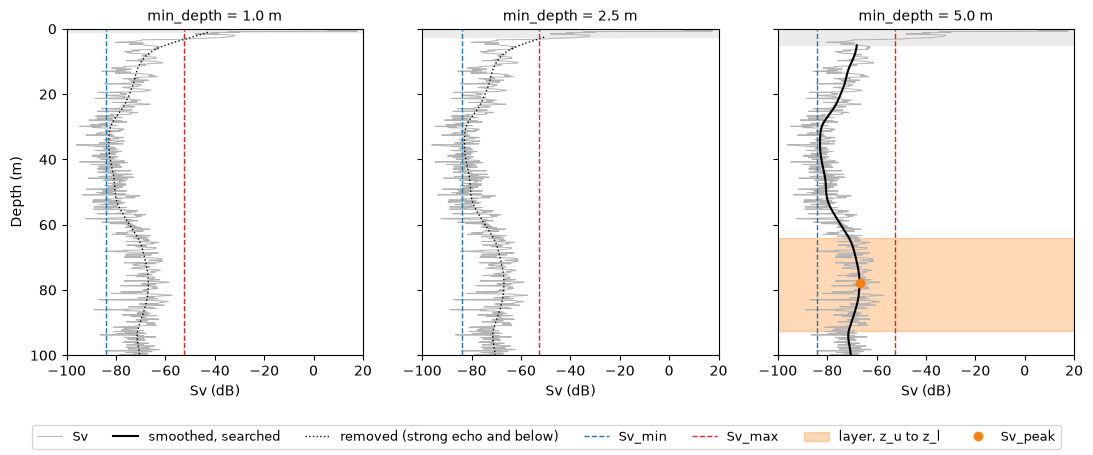

min_depth  1.0 m: layer found in  35.1% of pings


min_depth  2.5 m: layer found in  81.2% of pings


min_depth  5.0 m: layer found in  99.4% of pings


min_depth 10.0 m: layer found in 100.0% of pings


In [4]:
s, z = ssl.smooth(sv, depth, P["min_depth"], P["max_depth"], P["sigma"])
cut_at_top = s[:, 0] >= P["sv_max"]
i = int(np.flatnonzero(cut_at_top)[len(np.flatnonzero(cut_at_top)) // 2])

for ax in panels(i, "min_depth", (1.0, 2.5, 5.0), " m"):
    ax.set_xlim(-100, 20)
plt.show()

for top in (1.0, 2.5, 5.0, 10.0):
    r = ssl.detect(sv, depth, **{**P, "min_depth": top})
    print(f"min_depth {top:4.1f} m: layer found in {100 * r['found'].mean():5.1f}% of pings")

- **Too shallow (1 m):** in most pings the near-transducer echo is above `sv_max` at the top of the profile,
  so the profile ends at once and no layer is found.
- **2.5 m (the case-study setting):** in about a fifth of these pings, the echo still reaches `sv_max` just
  below 2.5 m. The profile then ends at once and no layer is found in that ping.
- **5 m or deeper:** the layer is found in almost every ping. A deeper top also hides any real layer above it.

## 2. Smoothing: `sigma`

The width (standard deviation, in metres) of the Gaussian filter applied along depth to the dB values. A
single ping is noisy, so without smoothing the layer breaks into many small peaks.

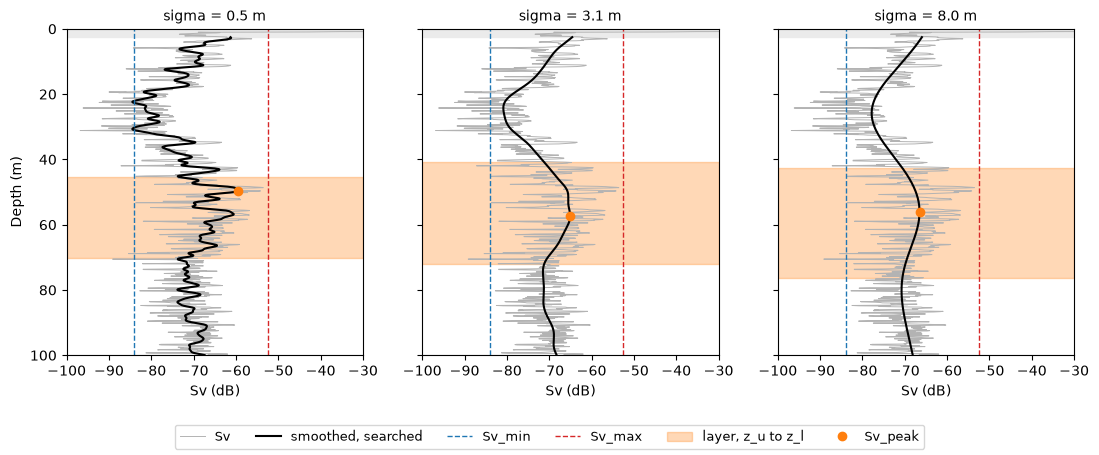

sigma  0.5 m: layer found in  60.7% of pings, median thickness  24.2 m


sigma  1.0 m: layer found in  67.2% of pings, median thickness  28.2 m


sigma  3.1 m: layer found in  81.2% of pings, median thickness  30.4 m


sigma  8.0 m: layer found in  82.4% of pings, median thickness  30.5 m


In [5]:
i = int(np.argmin(np.abs(T - mdates.date2num(np.datetime64("2024-06-05T23:00")))))
panels(i, "sigma", (0.5, 3.1, 8.0), " m")
plt.show()

for sg in (0.5, 1.0, 3.1, 8.0):
    r = ssl.detect(sv, depth, **{**P, "sigma": sg})
    print(f"sigma {sg:4.1f} m: layer found in {100 * r['found'].mean():5.1f}% of pings, "
          f"median thickness {np.nanmedian(r['z_l'] - r['z_u']):5.1f} m")

- **Small `sigma`:** the main peak is often one of the small bumps inside the layer, so the bounds jump
  from ping to ping. The very strong top echo is not spread out either, so it is more often removed as a
  strong echo.
- **Large `sigma`:** layers close together merge into one, and the edges are blurred.

## 3. Lower threshold: `sv_min`

Peaks weaker than `sv_min` are background. It is also the bottom of the intensity scale (I = 0).

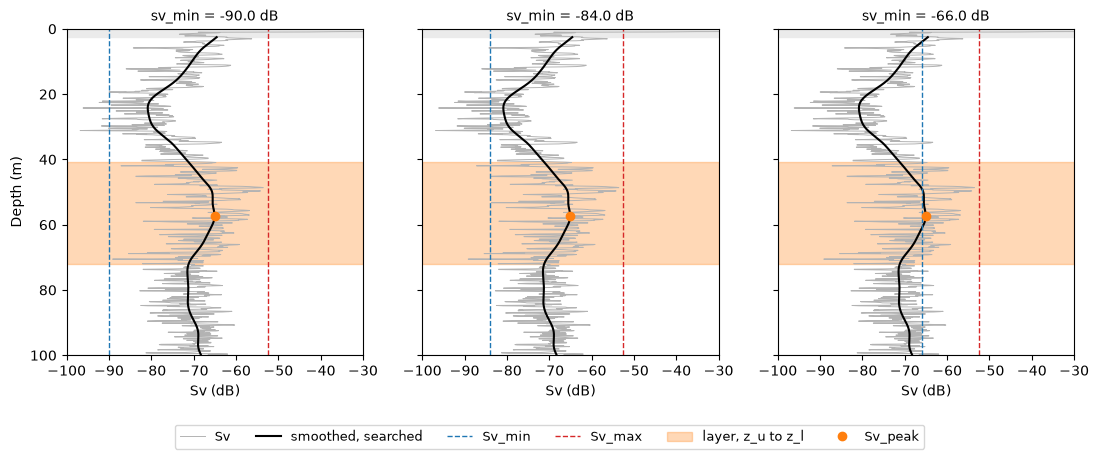

sv_min  -90.0 dB: layer found in  81.2% of pings, median I 0.66


sv_min  -84.0 dB: layer found in  81.2% of pings, median I 0.59


sv_min  -78.0 dB: layer found in  81.1% of pings, median I 0.50


sv_min  -72.0 dB: layer found in  80.9% of pings, median I 0.35


sv_min  -66.0 dB: layer found in  53.0% of pings, median I 0.13


In [6]:
panels(i, "sv_min", (-90.0, -84.0, -66.0), " dB")
plt.show()

for lo in (-90.0, -84.0, -78.0, -72.0, -66.0):
    r = ssl.detect(sv, depth, **{**P, "sv_min": lo})
    print(f"sv_min {lo:6.1f} dB: layer found in {100 * r['found'].mean():5.1f}% of pings, "
          f"median I {np.median(r['intensity'][r['found']]):.2f}")

In these data the layer stands well above the background, so `sv_min` changes little until it comes close to
the layer's own peak (about −65 dB). It matters for weak layers, and it shifts the intensity I.

## 4. Upper threshold: `sv_max`

Echoes at or above `sv_max` are treated as the seafloor or a dense school, and they are removed together
with everything below them. It is also the top of the intensity scale (I = 1). In this stretch the seafloor
is deeper than 100 m, so the strong echoes it removes are the near-transducer echoes from section 1. The ping
from section 1 is shown again.

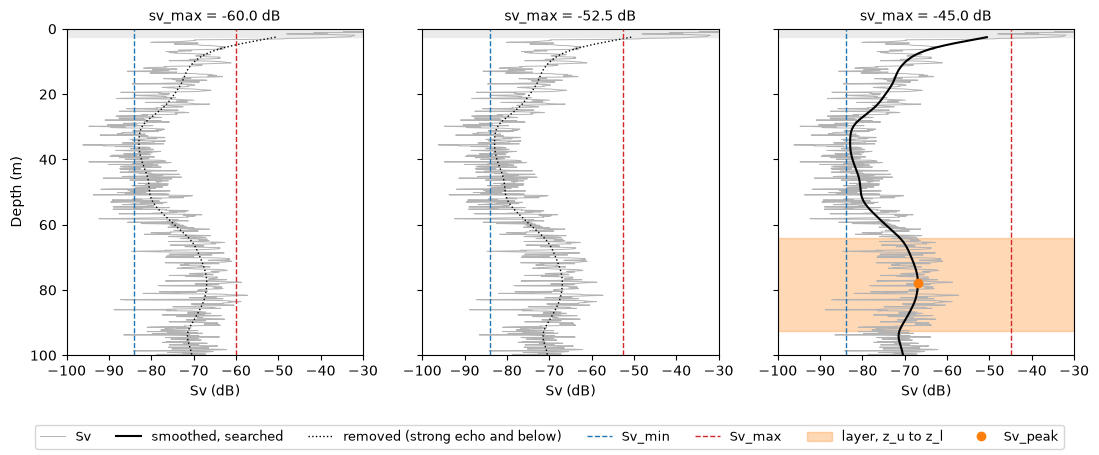

sv_max  -60.0 dB: layer found in  52.8% of pings


sv_max  -52.5 dB: layer found in  81.2% of pings


sv_max  -45.0 dB: layer found in  96.3% of pings


In [7]:
i_top = int(np.flatnonzero(cut_at_top)[len(np.flatnonzero(cut_at_top)) // 2])
panels(i_top, "sv_max", (-60.0, -52.5, -45.0), " dB")
plt.show()

for hi in (-60.0, -52.5, -45.0):
    r = ssl.detect(sv, depth, **{**P, "sv_max": hi})
    print(f"sv_max {hi:6.1f} dB: layer found in {100 * r['found'].mean():5.1f}% of pings")

- **Too low:** more pings end at the near-surface echo, and a strong layer could be removed as a strong echo.
- **Too high:** the seafloor or a school can be taken as the layer.

## 5. Where the bounds are read: `rel_height`

The bounds are where the smoothed profile has dropped below the peak by `rel_height` times the peak's
prominence (how far the peak stands above its surroundings). 0.5 gives the half-prominence width; values
near 1 reach down to the background on either side.

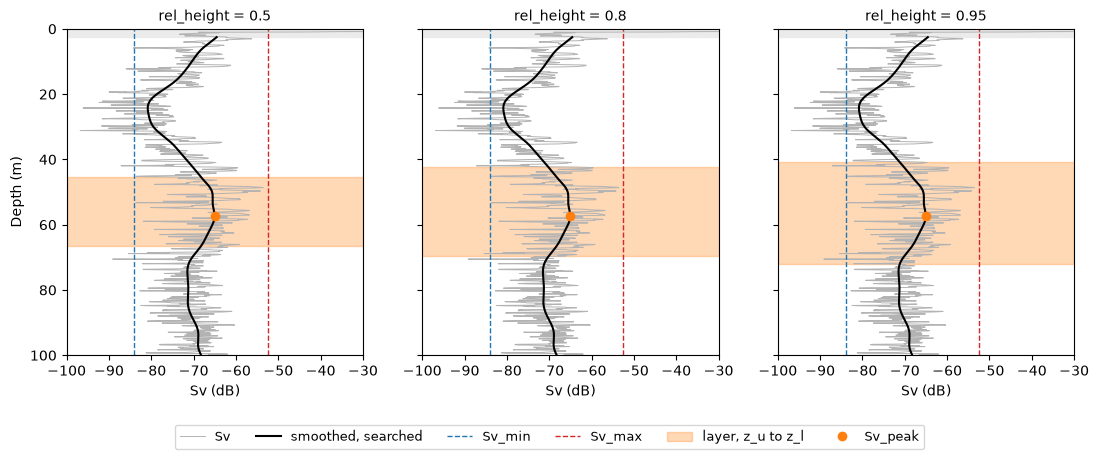

rel_height 0.50: median thickness  15.0 m


rel_height 0.80: median thickness  24.9 m


rel_height 0.95: median thickness  30.4 m


In [8]:
panels(i, "rel_height", (0.5, 0.8, 0.95))
plt.show()

for rh in (0.5, 0.8, 0.95):
    r = ssl.detect(sv, depth, **{**P, "rel_height": rh})
    print(f"rel_height {rh:4.2f}: median thickness {np.nanmedian(r['z_l'] - r['z_u']):5.1f} m")

## 6. All pings, with the case-study settings

The white dots are the bounds `z_u` and `z_l` of each ping, and the red dots are the peak depth.

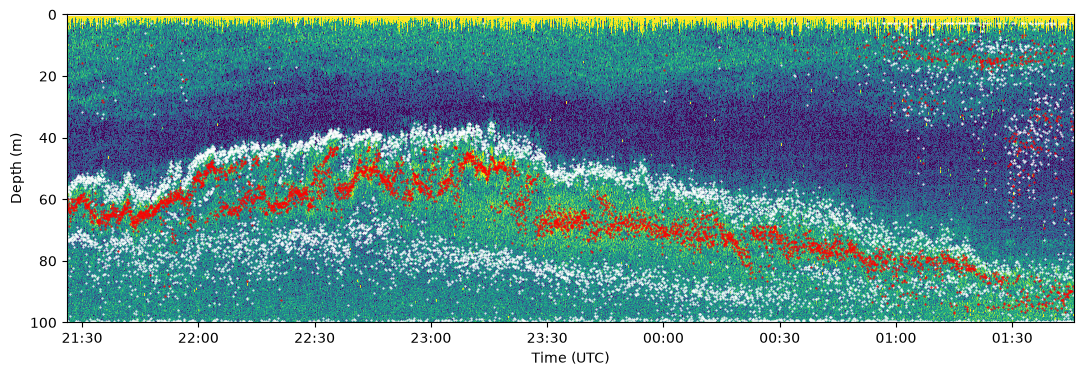

layer found in 81.2% of pings


In [9]:
r = ssl.detect(sv, depth, **P)
fig, ax = plt.subplots(figsize=(13, 4))
echogram(ax, r)
plt.show()
print(f"layer found in {100 * r['found'].mean():.1f}% of pings")

After about 01:20 the layer sinks to the bottom of the depth range, and the detector picks weaker
features above it.

Single pings are noisy, so the per-ping bounds are noisy as well. As the paper notes, they need filtering
over pings to give stable bounds. This filter is not part of the detector. Here, as an example, it is a
running median over 39 pings (about 2 minutes) that skips pings without a layer.

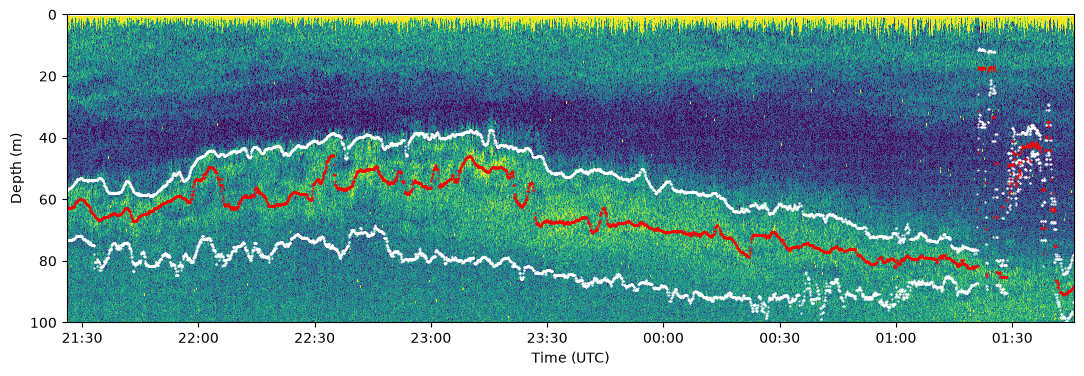

In [10]:
fig, ax = plt.subplots(figsize=(13, 4))
echogram(ax, r, median=39)
plt.show()

## 7. Tune it yourself

Move a slider and the detector runs again on all 5200 pings (this takes a few seconds). The left panel
shows the echogram with the bounds and the peak, and the right panel shows the ping marked by the dotted
line. `median` is the running median of section 6 (1 = off).

In [11]:
@lru_cache(maxsize=32)
def run(min_depth, max_depth, sigma, sv_min, sv_max, rel_height):
    return ssl.detect(sv, depth, min_depth, max_depth, sigma, sv_min, sv_max, rel_height)


style, wide = {"description_width": "90px"}, w.Layout(width="440px")
opts = dict(continuous_update=False, style=style, layout=wide)
ui = dict(
    depth_range=w.FloatRangeSlider(value=(P["min_depth"], P["max_depth"]), min=0, max=100, step=0.5,
                                   description="depth range", readout_format=".1f", **opts),
    sigma=w.FloatSlider(value=P["sigma"], min=0, max=10, step=0.1, description="sigma (m)", **opts),
    sv_min=w.FloatSlider(value=P["sv_min"], min=-100, max=-55, step=0.5, description="sv_min (dB)", **opts),
    sv_max=w.FloatSlider(value=P["sv_max"], min=-70, max=-20, step=0.5, description="sv_max (dB)", **opts),
    rel_height=w.FloatSlider(value=P["rel_height"], min=0.05, max=1, step=0.05, description="rel_height", **opts),
    median=w.IntSlider(value=1, min=1, max=101, step=2, description="median (pings)", **opts),
    ping=w.IntSlider(value=int(np.argmin(np.abs(T - mdates.date2num(np.datetime64("2024-06-05T23:00"))))),
                     min=0, max=len(T) - 1, description="ping", **opts),
)
reset = w.Button(description="case-study settings")


def back_to_paper(_):
    ui["depth_range"].value = (P["min_depth"], P["max_depth"])
    for k in ("sigma", "sv_min", "sv_max", "rel_height"):
        ui[k].value = P[k]
    ui["median"].value = 1


reset.on_click(back_to_paper)


def show(depth_range, sigma, sv_min, sv_max, rel_height, median, ping):
    if sv_min >= sv_max:
        print("sv_min must be below sv_max")
        return
    p = dict(min_depth=depth_range[0], max_depth=depth_range[1], sigma=sigma, sv_min=sv_min,
             sv_max=sv_max, rel_height=rel_height)
    r = run(*p.values())
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), sharey=True, gridspec_kw=dict(width_ratios=[3, 1]))
    echogram(a, r, median)
    a.axvline(T[ping], color="w", ls=":", lw=1)
    profile(b, ping, **p)
    plt.show()
    f = r["found"]
    if not f.any():
        print("no layer found in any ping")
        return
    print(f"layer found in {100 * f.mean():.1f}% of pings; medians: z_u {np.median(r['z_u'][f]):.1f} m, "
          f"z_l {np.median(r['z_l'][f]):.1f} m, I {np.median(r['intensity'][f]):.2f}")


out = w.interactive_output(show, ui)
left = w.VBox([ui[k] for k in ("depth_range", "sigma", "sv_min", "sv_max")])
right = w.VBox([ui[k] for k in ("rel_height", "median", "ping")] + [reset])
display(w.HBox([left, right]), out)